# Visualization (Only predicted data)

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os
import pandas as pd
import numpy as np


In [ ]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

In [2]:
# Define label mappings for demographic groups
label_mappings = {
    'sex_idx': {
        1: "Male",
        2: "Female"
    },
    'age_idx': {
        1: "18-24",
        2: "25-34",
        3: "35-44",
        4: "45-54",
        5: "55-64",
        6: "65+"
    },
    'eth_idx': {
        1: "White",
        2: "Black",
        3: "Hispanic",
        4: "Asian",
        5: "American Indian",
        6: "Other"
    },
    'income_idx': {
        1: "<$25k",
        2: "$25k-$50k",
        3: "$50k-$75k",
        4: "$75k-$100k",
        5: ">$100k"
    },
    'vote_idx': {
        1: "Did not vote",
        2: "Republican",
        3: "Democrat",
        4: "Libertarian",
        5: "Green",
        6: "Other"
    },
    'state_idx': {
        1: "AL", 2: "AK", 3: "AZ", 4: "AR", 5: "CA", 6: "CO", 7: "CT", 8: "DE", 9: "FL", 10: "GA",
        11: "HI", 12: "ID", 13: "IL", 14: "IN", 15: "IA", 16: "KS", 17: "KY", 18: "LA", 19: "ME", 20: "MD",
        21: "MA", 22: "MI", 23: "MN", 24: "MS", 25: "MO", 26: "MT", 27: "NE", 28: "NV", 29: "NH", 30: "NJ",
        31: "NM", 32: "NY", 33: "NC", 34: "ND", 35: "OH", 36: "OK", 37: "OR", 38: "PA", 39: "RI", 40: "SC",
        41: "SD", 42: "TN", 43: "TX", 44: "UT", 45: "VT", 46: "VA", 47: "WA", 48: "WV", 49: "WI", 50: "WY"
    }
}

def apply_labels(data, group_col):
    """
    Apply labels to group column values.
    
    Parameters:
    - data: DataFrame with group column
    - group_col: Name of the group column
    
    Returns:
    - DataFrame with renamed group values
    """
    data = data.copy()
    if group_col in label_mappings:
        data[group_col] = data[group_col].map(label_mappings[group_col]).fillna(data[group_col])
    return data

print("Label mappings loaded successfully!")

Label mappings loaded successfully!


In [4]:
base_dir = "/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Nominal_January"

In [5]:
belief_col = "Belief_opinion_on_january_6th_storming_of_the_us_capitol_Symbol"

In [6]:
# Load consolidated time series data for each demographic group
def load_group_timeseries(base_dir, group_name):
    """Load time series predictions for a demographic group."""
    file_path = f"{base_dir}/group_{group_name}_category_probs_timeseries.csv"
    if os.path.exists(file_path):
        return pd.read_csv(file_path)
    else:
        print(f"Warning: {file_path} not found")
        return None

# Load all available group time series
groups_to_load = ['sex', 'age', 'eth', 'income', 'vote', 'state']
group_data = {}

for gname in groups_to_load:
    data = load_group_timeseries(base_dir, gname)
    if data is not None:
        group_data[gname] = data
        print(f"Loaded {gname}: {len(data)} rows, {data['time_window_start'].nunique()} time windows")

print(f"\nAvailable groups: {list(group_data.keys())}")

Loaded sex: 156 rows, 26 time windows
Loaded age: 468 rows, 26 time windows
Loaded eth: 468 rows, 26 time windows
Loaded income: 390 rows, 26 time windows
Loaded vote: 468 rows, 26 time windows
Loaded state: 3978 rows, 26 time windows

Available groups: ['sex', 'age', 'eth', 'income', 'vote', 'state']


In [7]:
# Function: Plot category probabilities over time for specific groups
def plot_category_timeseries(data, group_col, group_values=None, figsize=(14, 8), 
                             title_prefix="", ncols=2, save_path=None):
    """
    Plot category probability time series for selected group values.
    
    Parameters:
    - data: DataFrame with columns [group_col, category, prob_mean, time_window_start]
    - group_col: Name of the grouping column
    - group_values: List of specific group values to plot (None = plot all)
    - figsize: Figure size
    - title_prefix: Prefix for plot title
    - ncols: Number of columns in subplot grid
    - save_path: Path to save the figure (None = don't save)
    """
    if data is None or len(data) == 0:
        print(f"No data available for {group_col}")
        return
    
    # Filter to specific group values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found in {group_col}")
        return
    
    # Convert time windows to datetime for better plotting
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("husl", len(categories))
    
    # Find global y-axis limits across all groups
    all_probs = data['prob_mean'].values
    global_ymin = np.min(all_probs) - 0.05
    global_ymax = np.max(all_probs) + 0.05
    global_ymin = max(0, global_ymin)
    global_ymax = min(1, global_ymax)
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        for cat_idx, cat in enumerate(categories):
            cat_data = group_subset[group_subset['category'] == cat].sort_values('time_dt')
            ax.plot(cat_data['time_dt'], cat_data['prob_mean'], 
                   marker='o', label=f'Category {cat}', color=colors[cat_idx], linewidth=2)
        
        ax.set_title(f"{title_prefix}{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Probability')
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim([global_ymin, global_ymax])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_timeseries()")


Function loaded: plot_category_timeseries()


In [8]:
# Plot expected value time series with 95% credible intervals for a demographic group
def plot_expected_value_trends(base_dir, belief_col, group_name, group_values=None, 
                               figsize=(14, 6), ncols=2, save_path=None):
    
    # Load predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        print(f"No prediction files found for {group_name}")
        return
    
    data = pd.concat(all_preds, ignore_index=True)
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Determine group column name
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in data.columns else group_name)
    
    if group_col not in data.columns:
        print(f"Group column {group_col} not found")
        return
    
    # Filter to specific values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups to plot")
        return
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    # Find global y-axis limits across all groups
    global_ymin = data['pred_lower'].min() - 0.05
    global_ymax = data['pred_upper'].max() + 0.05
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_data = data[data[group_col] == group_val].sort_values('time_dt')
        
        # Plot mean with CI ribbon
        ax.plot(group_data['time_dt'], group_data['pred_mean'], 
               marker='o', linewidth=2.5, color='steelblue', label='Mean')
        ax.fill_between(group_data['time_dt'], 
                        group_data['pred_lower'], 
                        group_data['pred_upper'],
                        alpha=0.3, color='steelblue', label='95% CI')
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.legend(loc='best')
        ax.grid(True, alpha=0.3)
        ax.set_ylim([global_ymin, global_ymax])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Expected Value Trends: {group_name.capitalize()} Groups', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_expected_value_trends()")


Function loaded: plot_expected_value_trends()


In [9]:
# Create stacked area plots showing category probability evolution over time
def plot_category_stacked_area(data, group_col, group_values=None, figsize=(14, 8), ncols=2, save_path=None):
    
    if group_values is not None: # Filter to specific group values
        data = data[data[group_col].isin(group_values)].copy()
    
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found")
        return
    
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("RdYlGn", len(categories))
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        # Pivot to wide format for stacking
        pivot_data = group_subset.pivot(index='time_dt', columns='category', values='prob_mean')
        pivot_data = pivot_data.fillna(0).sort_index()
        
        # Stacked area plot
        ax.stackplot(pivot_data.index, 
                    *[pivot_data[cat] for cat in categories],
                    labels=[f'Cat {cat}' for cat in categories],
                    colors=colors, alpha=0.8)
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Category Probability')
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
        ax.set_ylim([0, 1])
        ax.grid(True, alpha=0.3, axis='y')
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_stacked_area()")


Function loaded: plot_category_stacked_area()


In [10]:
plots_dir = f"{base_dir}/visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Nominal_January/visualizations



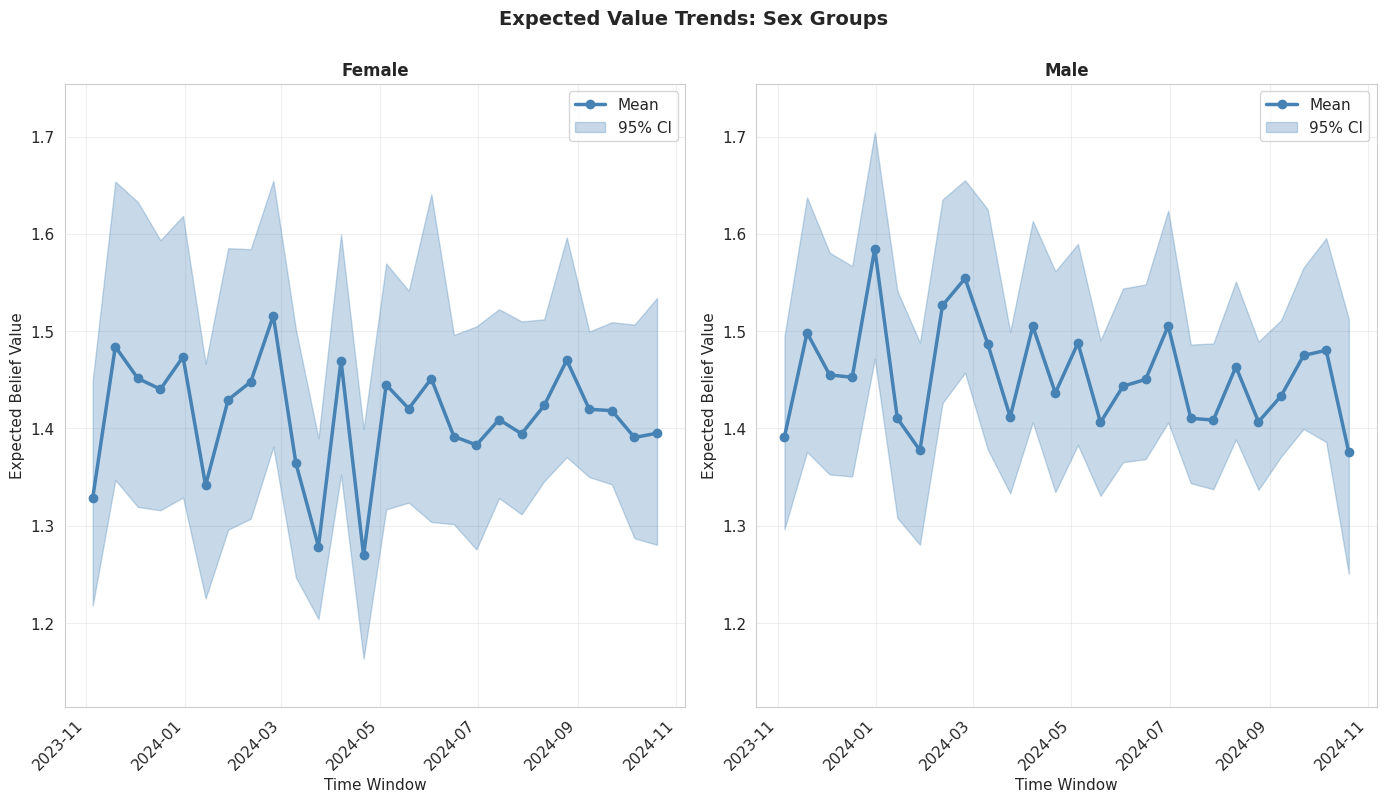

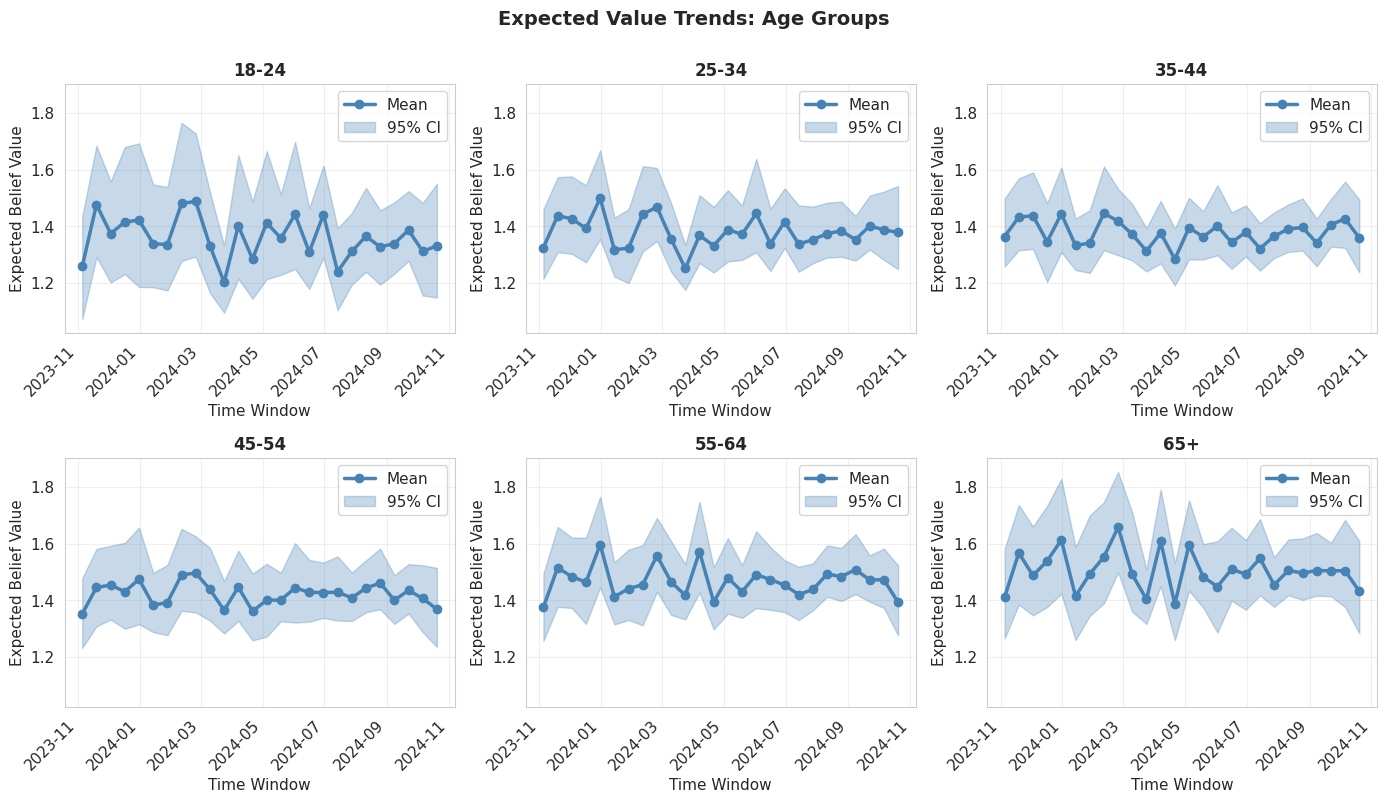

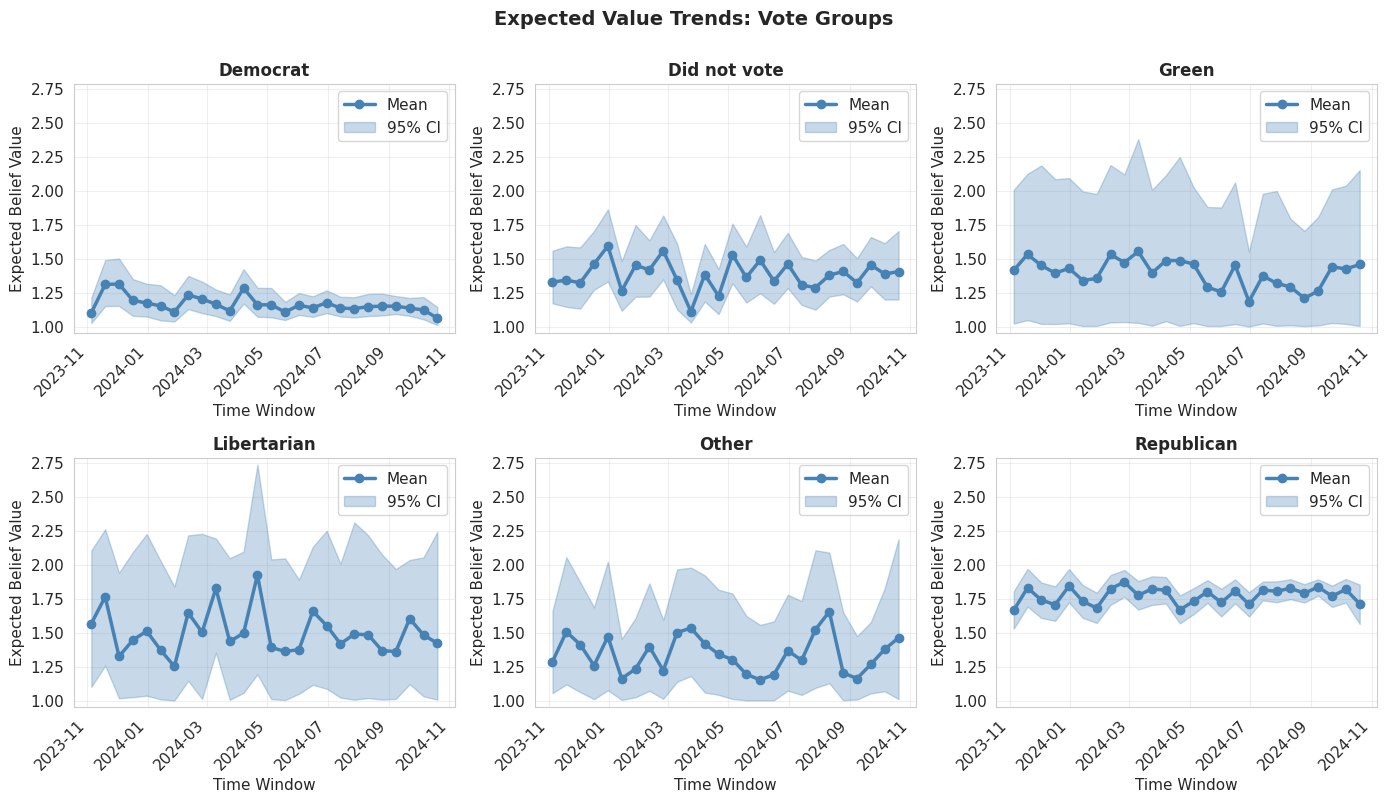

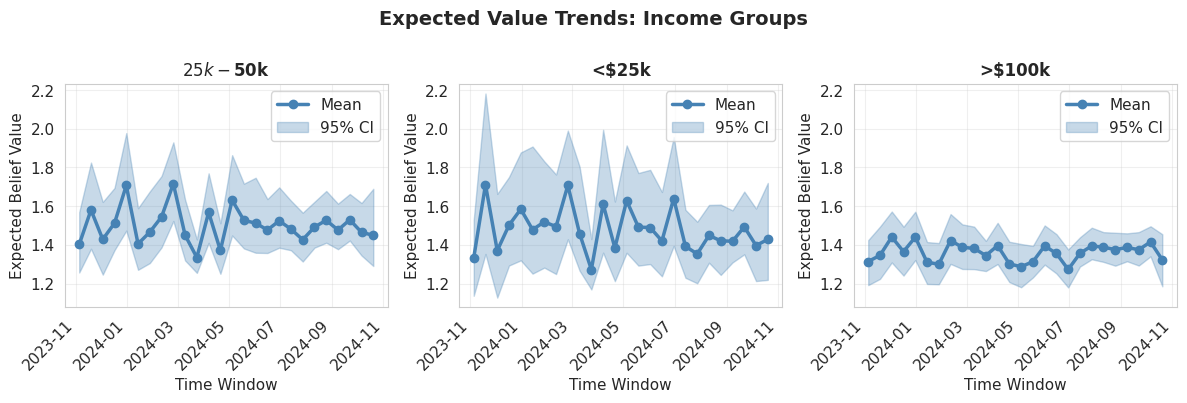

In [13]:
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='sex',
    figsize=(14, 8),
    ncols=2,

)


plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3
)

plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='vote',
    figsize=(14, 8),
    ncols=3
)


plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='income',
    group_values=[1, 2, 5],  
    figsize=(12, 4),
    ncols=3
)

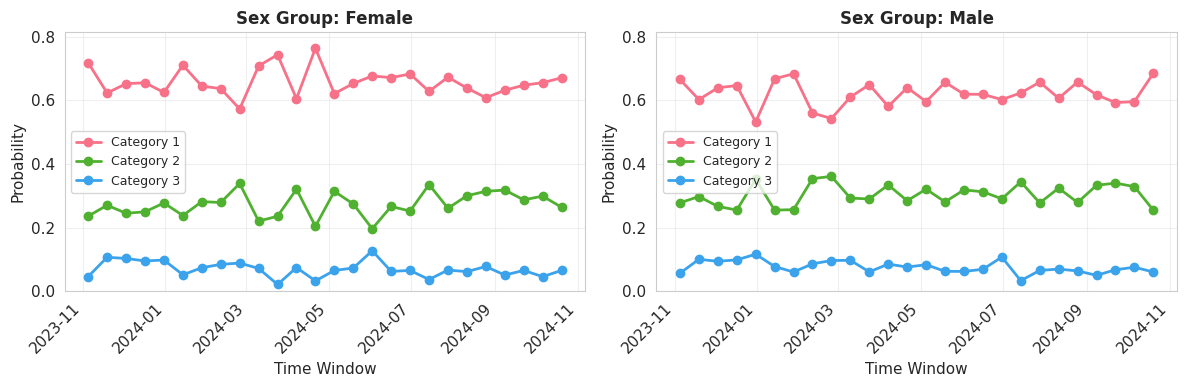

In [14]:
# Category probabilities over time by sex
if 'sex' in group_data:
    plot_category_timeseries(
        group_data['sex'], 
        group_col='sex_idx',
        title_prefix="Sex Group: ",
        figsize=(12, 4),
        ncols=2
    )

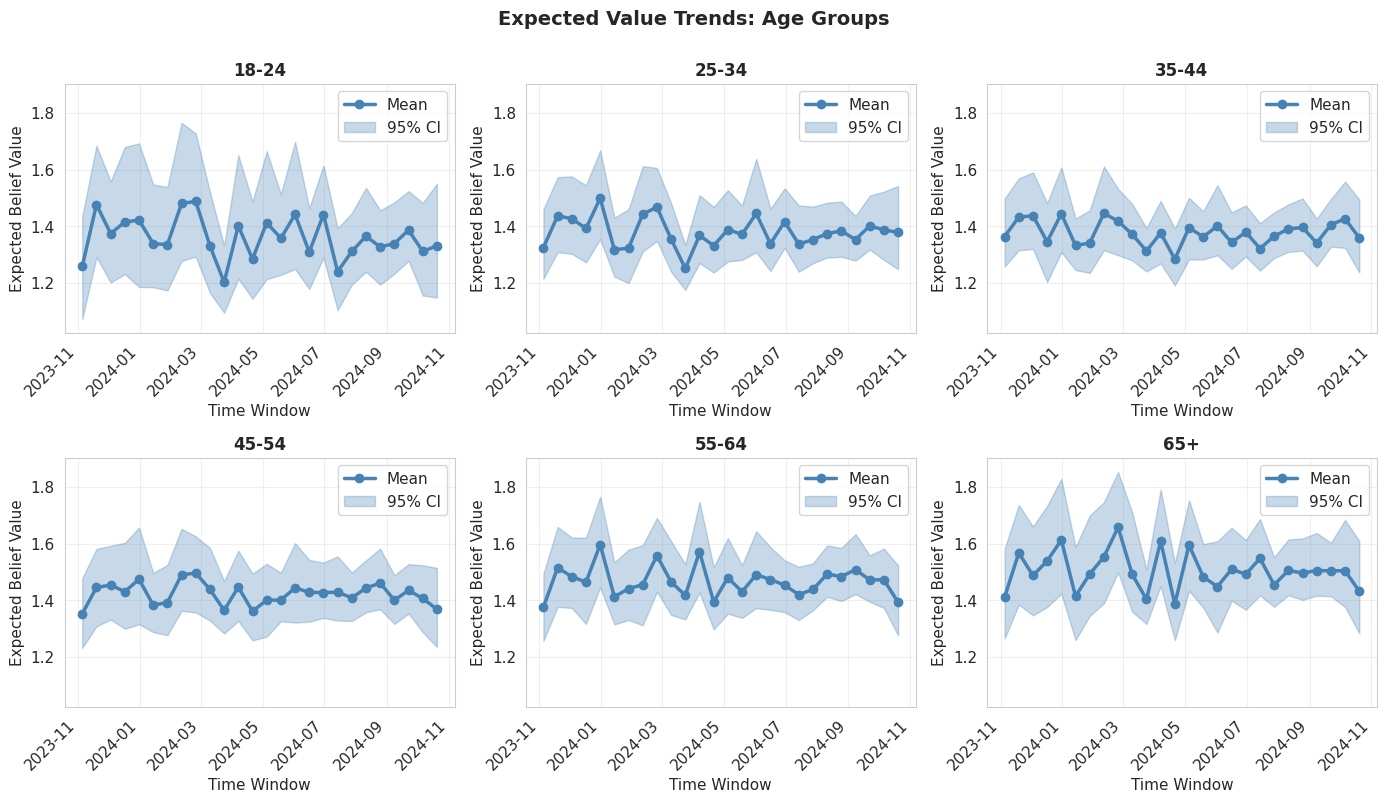

In [15]:
# Expected value trends with uncertainty by age group
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3
)

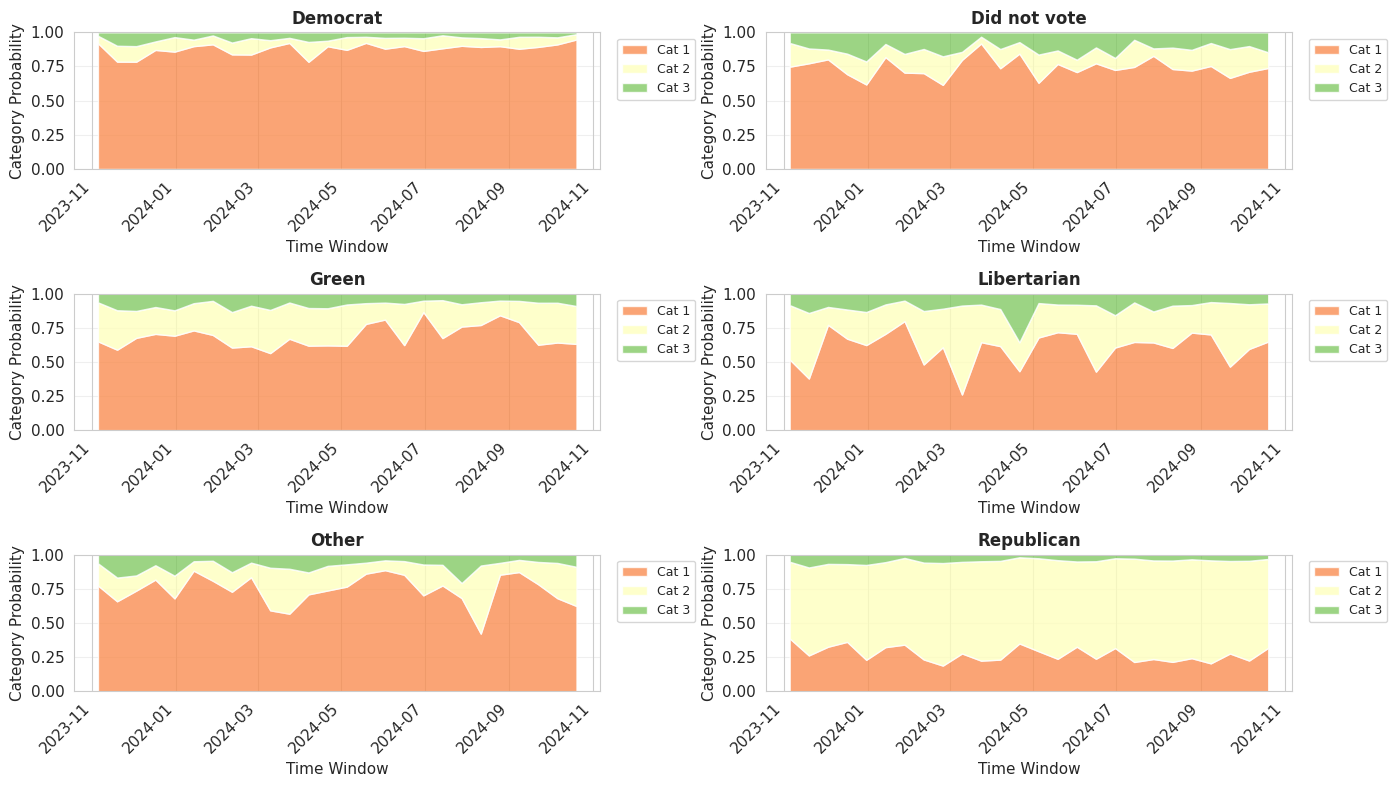

In [16]:
# Stacked area plot for past vote groups
if 'vote' in group_data:
    plot_category_stacked_area(
        group_data['vote'],
        group_col='vote_idx',
        figsize=(14, 8),
        ncols=2
    )

# Validating result with external sources

In [18]:
# Define baseline ground truth data from external sources
baseline_data = {
    'National': {
        'vote_idx': None,
        'probs': [0.56, 0.17, 0.17],  # cat1, cat2, cat3
    },
    'Biden Supporter': {
        'vote_idx': 3,  # Democrat
        'probs': [0.86, 0.05, 0.08],
    },
    'Trump Supporter': {
        'vote_idx': 2,  # Republican
        'probs': [0.12, 0.40, 0.40],
    }
}

# Calculate expected values for each baseline
for label, data in baseline_data.items():
    K = 3  # number of categories
    categories = np.arange(1, K + 1)
    expected_value = np.sum(np.array(data['probs']) * categories)
    data['expected_value'] = expected_value
    print(f"{label}: Probs={data['probs']}, Expected Value={expected_value:.3f}")


National: Probs=[0.56, 0.17, 0.17], Expected Value=1.410
Biden Supporter: Probs=[0.86, 0.05, 0.08], Expected Value=1.200
Trump Supporter: Probs=[0.12, 0.4, 0.4], Expected Value=2.120


In [19]:
# Function: Plot category probabilities with baseline comparison
def plot_category_with_baseline(base_dir, belief_col, group_name, baseline_data, 
                                figsize=(14, 6), ncols=2, save_path=None):
    """
    Plot category probabilities for groups with baseline reference lines.
    
    Parameters:
    - base_dir: Base directory for predictions
    - belief_col: Belief column name
    - group_name: Group name (e.g., 'vote')
    - baseline_data: Dictionary with baseline information
    - figsize: Figure size
    - ncols: Number of columns in subplot grid
    - save_path: Path to save the figure
    """
    # Load consolidated category probabilities timeseries
    cons_file = f"{base_dir}/group_{group_name}_category_probs_timeseries.csv"
    if not os.path.exists(cons_file):
        print(f"No consolidated file found: {cons_file}")
        print(f"Available files in {base_dir}:")
        try:
            files = [f for f in os.listdir(base_dir) if f.startswith('group_')]
            print(f"  {files}")
        except:
            pass
        return
    
    data = pd.read_csv(cons_file)
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Map group_idx to labels for comparison
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else group_name
    
    # Get only groups that have baselines
    groups_to_plot = []
    for baseline_label, baseline_info in baseline_data.items():
        if baseline_info.get('vote_idx') is not None:
            if baseline_info['vote_idx'] in data[group_col].values:
                groups_to_plot.append((baseline_label, baseline_info['vote_idx']))
        else:
            # National average - we'll compute this from all data
            groups_to_plot.append((baseline_label, 'national'))
    
    nrows = int(np.ceil(len(groups_to_plot) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("Set2", len(categories))
    
    for idx, (baseline_label, group_idx) in enumerate(groups_to_plot):
        ax = axes[idx]
        baseline_info = baseline_data[baseline_label]
        
        if group_idx == 'national':
            # National: aggregate across all data
            for cat_idx, cat in enumerate(categories):
                cat_data = data[data['category'] == cat].groupby('time_dt').agg({
                    'prob_mean': 'mean',
                    'prob_lower': 'mean',
                    'prob_upper': 'mean'
                }).reset_index().sort_values('time_dt')
                
                ax.plot(cat_data['time_dt'], cat_data['prob_mean'], 
                       marker='o', label=f'Model Cat {cat}', color=colors[cat_idx], linewidth=2)
                ax.fill_between(cat_data['time_dt'], 
                               cat_data['prob_lower'], 
                               cat_data['prob_upper'],
                               alpha=0.2, color=colors[cat_idx])
        else:
            # Specific group
            for cat_idx, cat in enumerate(categories):
                cat_data = data[(data['category'] == cat) & (data[group_col] == group_idx)]
                if len(cat_data) > 0:
                    cat_data = cat_data.sort_values('time_dt')[['time_dt', 'prob_mean', 'prob_lower', 'prob_upper']]
                    ax.plot(cat_data['time_dt'], cat_data['prob_mean'], 
                           marker='o', label=f'Model Cat {cat}', color=colors[cat_idx], linewidth=2)
                    ax.fill_between(cat_data['time_dt'], 
                                   cat_data['prob_lower'], 
                                   cat_data['prob_upper'],
                                   alpha=0.2, color=colors[cat_idx])
        
        # Add baseline horizontal lines
        for cat_idx, cat in enumerate(categories):
            baseline_prob = baseline_info['probs'][cat_idx]
            ax.axhline(y=baseline_prob, color=colors[cat_idx], linestyle='--', 
                      linewidth=2, alpha=0.7, label=f'Baseline Cat {cat}: {baseline_prob:.1%}')
        
        ax.set_title(f"{baseline_label}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Category Probability')
        ax.legend(loc='best', fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0, 1])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(len(groups_to_plot), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Model Predictions vs Baseline: {group_name.capitalize()} Groups', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_with_baseline()")


Function loaded: plot_category_with_baseline()


In [20]:
# Plot expected value time series with 95% credible intervals for a demographic group
def plot_expected_value_with_baseline(base_dir, belief_col, group_name, baseline_data,
                                      figsize=(14, 6), ncols=2, save_path=None):
    """
    Plot expected values for groups with baseline reference lines.
    
    Parameters:
    - base_dir: Base directory for predictions
    - belief_col: Belief column name
    - group_name: Group name (e.g., 'vote')
    - baseline_data: Dictionary with baseline information
    - figsize: Figure size
    - ncols: Number of columns in subplot grid
    - save_path: Path to save the figure
    """
    # Load predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        print(f"No prediction files found for {group_name}")
        return
    
    data = pd.concat(all_preds, ignore_index=True)
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Determine group column name 
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in data.columns else group_name)
    
    if group_col not in data.columns:
        print(f"Group column {group_col} not found")
        print(f"Available columns: {data.columns.tolist()}")
        return
    
    # Get groups that have baselines (filter BEFORE applying labels)
    groups_to_plot = []
    for baseline_label, baseline_info in baseline_data.items():
        if baseline_info.get('vote_idx') is not None:
            # Check if this group exists in data by vote_idx
            if baseline_info['vote_idx'] in data[group_col].values:
                groups_to_plot.append((baseline_label, baseline_info['vote_idx']))
                print(f"  Found {baseline_label} (vote_idx={baseline_info['vote_idx']})")
            else:
                print(f"  Warning: {baseline_label} (vote_idx={baseline_info['vote_idx']}) not found in data")
        else:
            # National average - compute from all data
            groups_to_plot.append((baseline_label, 'national'))
            print(f"  Found {baseline_label} (national)")
    
    print(f"Groups to plot: {groups_to_plot}\n")
    
    nrows = int(np.ceil(len(groups_to_plot) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    # Find global y-axis limits
    global_ymin = data['pred_lower'].min() - 0.1
    global_ymax = data['pred_upper'].max() + 0.1
    
    for idx, (baseline_label, group_idx) in enumerate(groups_to_plot):
        ax = axes[idx]
        baseline_info = baseline_data[baseline_label]
        baseline_ev = baseline_info['expected_value']
        
        if group_idx == 'national':
            # National: aggregate expected values across all data
            group_data = data.groupby('time_dt').agg({
                'pred_mean': 'mean',
                'pred_lower': 'mean',
                'pred_upper': 'mean'
            }).reset_index().sort_values('time_dt')
        else:
            # Specific group - filter by numeric index FIRST
            group_data = data[data[group_col] == group_idx].sort_values('time_dt')
        
        if len(group_data) == 0:
            print(f"Warning: No data for {baseline_label}")
            continue
        
        # Now apply labels for display
        display_label = label_mappings.get(group_col, {}).get(group_idx, str(group_idx)) if group_idx != 'national' else 'National'
        
        # Plot model predictions
        ax.plot(group_data['time_dt'], group_data['pred_mean'], 
               marker='o', linewidth=2.5, color='steelblue', label='Model Mean')
        ax.fill_between(group_data['time_dt'], 
                        group_data['pred_lower'], 
                        group_data['pred_upper'],
                        alpha=0.3, color='steelblue', label='95% CI')
        
        # Add baseline horizontal line
        ax.axhline(y=baseline_ev, color='red', linestyle='--', linewidth=2.5, 
                  alpha=0.8, label=f'Baseline: {baseline_ev:.3f}')
        
        # Calculate and display difference
        latest_pred = group_data['pred_mean'].iloc[-1] if len(group_data) > 0 else None
        if latest_pred is not None:
            diff = latest_pred - baseline_ev
            ax.text(0.05, 0.95, f'Latest diff: {diff:+.3f}', 
                   transform=ax.transAxes, fontsize=10, verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        ax.set_title(f"{baseline_label}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim([global_ymin, global_ymax])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(len(groups_to_plot), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Expected Value: Model vs Baseline ({group_name.capitalize()} Groups)', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_expected_value_with_baseline()")

Function loaded: plot_expected_value_with_baseline()


In [21]:
# Function: Create validation summary table
def validation_summary_table(base_dir, belief_col, group_name, baseline_data):
    """
    Create a summary table comparing model predictions with baselines.
    
    Parameters:
    - base_dir: Base directory for predictions
    - belief_col: Belief column name
    - group_name: Group name (e.g., 'vote')
    - baseline_data: Dictionary with baseline information
    
    Returns:
    - DataFrame with validation summary
    """
    # Load predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        print(f"No prediction files found for {group_name}")
        return None
    
    data = pd.concat(all_preds, ignore_index=True)
    
    # Determine group column name
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in data.columns else group_name)
    
    if group_col not in data.columns:
        print(f"Group column {group_col} not found")
        return None
    
    # Apply labels
    data = apply_labels(data, group_col)
    
    summary_rows = []
    
    for baseline_label, baseline_info in baseline_data.items():
        if baseline_info['vote_idx'] is not None:
            group_idx = baseline_info['vote_idx']
            # Check if this group exists
            if group_idx not in data[group_col].values:
                continue
            group_data = data[data[group_col] == group_idx]
            group_label = label_mappings.get(f'{group_name}_idx', {}).get(group_idx, str(group_idx))
        else:
            # National average
            group_data = data
            group_label = 'National (All)'
        
        # Get latest time window prediction
        latest_window = group_data['time_window_start'].max()
        latest_data = group_data[group_data['time_window_start'] == latest_window]
        
        if len(latest_data) > 0:
            pred_mean = latest_data['pred_mean'].values[0]
            pred_lower = latest_data['pred_lower'].values[0]
            pred_upper = latest_data['pred_upper'].values[0]
        else:
            pred_mean = pred_lower = pred_upper = np.nan
        
        baseline_ev = baseline_info['expected_value']
        diff = pred_mean - baseline_ev if not np.isnan(pred_mean) else np.nan
        pct_diff = (diff / baseline_ev * 100) if not np.isnan(diff) and baseline_ev != 0 else np.nan
        
        summary_rows.append({
            'Group': baseline_label,
            'Model_Label': group_label,
            'Baseline_EV': f"{baseline_ev:.4f}",
            'Baseline_Probs': f"{baseline_info['probs']}",
            'Model_EV_Mean': f"{pred_mean:.4f}",
            'Model_EV_Lower': f"{pred_lower:.4f}",
            'Model_EV_Upper': f"{pred_upper:.4f}",
            'Diff': f"{diff:+.4f}" if not np.isnan(diff) else "N/A",
            'Pct_Diff': f"{pct_diff:+.2f}%" if not np.isnan(pct_diff) else "N/A",
            'Latest_Window': latest_window
        })
    
    return pd.DataFrame(summary_rows)

print("Function loaded: validation_summary_table()")


Function loaded: validation_summary_table()


In [22]:
# Validation Analysis: Category Probabilities vs Baselines
print("="*80)
print("VALIDATION: Model Predictions vs Ground Truth Baselines")
print("="*80)

# Create validation summary
val_summary = validation_summary_table(base_dir, belief_col, 'vote', baseline_data)
if val_summary is not None:
    print("\nValidation Summary Table:")
    print(val_summary.to_string(index=False))
    
    # Save to CSV
    val_summary.to_csv(f"{base_dir}/validation_summary_vote.csv", index=False)
    print(f"\nValidation summary saved to: {base_dir}/validation_summary_vote.csv")


VALIDATION: Model Predictions vs Ground Truth Baselines

Validation Summary Table:
   Group    Model_Label Baseline_EV     Baseline_Probs Model_EV_Mean Model_EV_Lower Model_EV_Upper    Diff Pct_Diff             Latest_Window
National National (All)      1.4100 [0.56, 0.17, 0.17]        1.4069         1.2015         1.7046 -0.0031   -0.22% 2024-10-20 00:00:00+00:00

Validation summary saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Nominal_January/validation_summary_vote.csv


Figure saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Nominal_January/validation_category_probs_vs_baseline.png


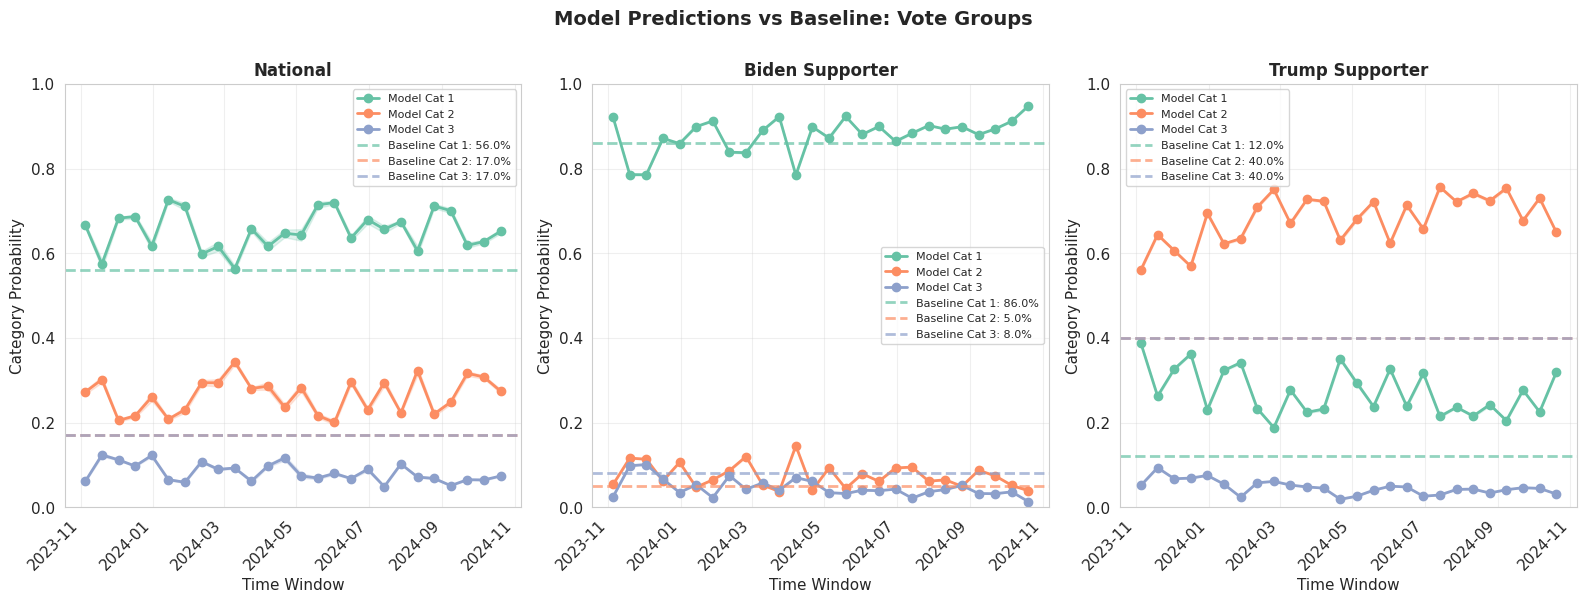

In [23]:
# Visualization 1: Category Probabilities with Baselines (Vote Group)
plot_category_with_baseline(
    base_dir,
    belief_col,
    group_name='vote',
    baseline_data=baseline_data,
    figsize=(16, 6),
    ncols=3,
    save_path=f"{base_dir}/validation_category_probs_vs_baseline.png"
)


  Found National (national)
  Found Biden Supporter (vote_idx=3)
  Found Trump Supporter (vote_idx=2)
Groups to plot: [('National', 'national'), ('Biden Supporter', 3), ('Trump Supporter', 2)]

Figure saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Nominal_January/validation_expected_value_vs_baseline.png


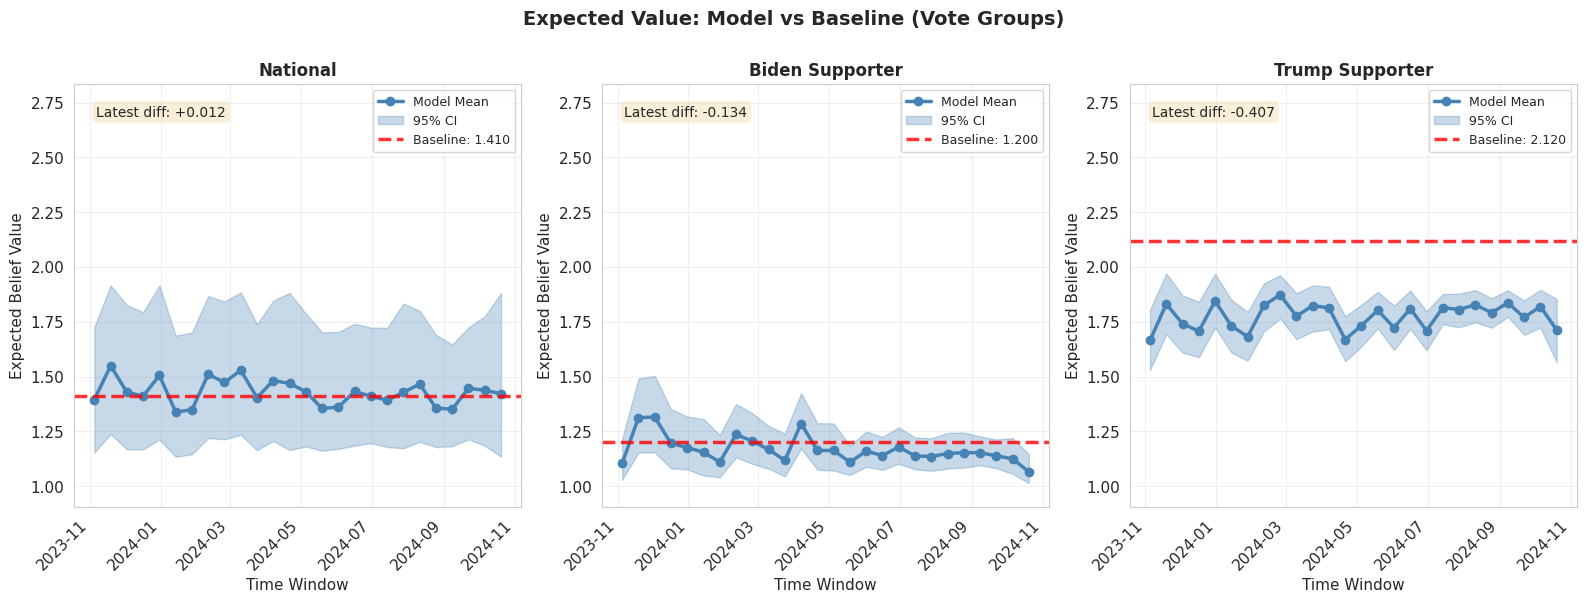

In [24]:
# Visualization 2: Expected Values with Baselines (Vote Group)
plot_expected_value_with_baseline(
    base_dir,
    belief_col,
    group_name='vote',
    baseline_data=baseline_data,
    figsize=(16, 6),
    ncols=3,
    save_path=f"{base_dir}/validation_expected_value_vs_baseline.png"
)
